# Assignment 2

In this assigment, we will work with the *Forest Fire* data set. Please download the data from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/162/forest+fires). Extract the data files into the subdirectory: `../data/fires/` (relative to `./05_src/`).

## Objective

+ The model objective is to predict the area affected by forest fires given the features set. 
+ The objective of this exercise is to assess your ability to construct and evaluate model pipelines.
+ Please note: the instructions are not meant to be 100% prescriptive, but instead they are a set of minimum requirements. If you find predictive performance gains by applying additional steps, by all means show them. 

## Variable Description

From the description file contained in the archive (`forestfires.names`), we obtain the following variable descriptions:

1. X - x-axis spatial coordinate within the Montesinho park map: 1 to 9
2. Y - y-axis spatial coordinate within the Montesinho park map: 2 to 9
3. month - month of the year: "jan" to "dec" 
4. day - day of the week: "mon" to "sun"
5. FFMC - FFMC index from the FWI system: 18.7 to 96.20
6. DMC - DMC index from the FWI system: 1.1 to 291.3 
7. DC - DC index from the FWI system: 7.9 to 860.6 
8. ISI - ISI index from the FWI system: 0.0 to 56.10
9. temp - temperature in Celsius degrees: 2.2 to 33.30
10. RH - relative humidity in %: 15.0 to 100
11. wind - wind speed in km/h: 0.40 to 9.40 
12. rain - outside rain in mm/m2 : 0.0 to 6.4 
13. area - the burned area of the forest (in ha): 0.00 to 1090.84 









### Specific Tasks

+ Construct four model pipelines, out of combinations of the following components:

    + Preprocessors:

        - A simple processor that only scales numeric variables and recodes categorical variables.
        - A transformation preprocessor that scales numeric variables and applies a non-linear transformation.
    
    + Regressor:

        - A baseline regressor, which could be a [K-nearest neighbours model]() or a linear model like [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) or [Ridge Regressors](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ridge_regression.html).
        - An advanced regressor of your choice (e.g., Bagging, Boosting, SVR, etc.). TIP: select a tree-based method such that it does not take too long to run SHAP further below. 

+ Evaluate tune and evaluate each of the four model pipelines. 

    - Select a [performance metric](https://scikit-learn.org/stable/modules/linear_model.html) out of the following options: explained variance, max error, root mean squared error (RMSE), mean absolute error (MAE), r-squared.
    - *TIPS*: 
    
        * Out of the suggested metrics above, [some are correlation metrics, but this is a prediction problem](https://www.tmwr.org/performance#performance). Choose wisely (and don't choose the incorrect options.) 

+ Select the best-performing model and explain its predictions.

    - Provide local explanations.
    - Obtain global explanations and recommend a variable selection strategy.

+ Export your model as a pickle file.


You can work on the Jupyter notebook, as this experiment is fairly short (no need to use sacred). 

# Load the data

Place the files in the ../../05_src/data/fires/ directory and load the appropriate file. 

In [10]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error


In [11]:
# Load data
columns = [
    'coord_x', 'coord_y', 'month', 'day', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain', 'area' 
]
fires_dt = (pd.read_csv('C:\\Users\\param\\OneDrive\\Desktop\\DSI\\Machine Learning - Repo\\production\\05_src\\data\\fires\\forestfires.csv', header = 0, names = columns))
fires_dt.info()


<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   coord_x  517 non-null    int64  
 1   coord_y  517 non-null    int64  
 2   month    517 non-null    str    
 3   day      517 non-null    str    
 4   ffmc     517 non-null    float64
 5   dmc      517 non-null    float64
 6   dc       517 non-null    float64
 7   isi      517 non-null    float64
 8   temp     517 non-null    float64
 9   rh       517 non-null    int64  
 10  wind     517 non-null    float64
 11  rain     517 non-null    float64
 12  area     517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 55.7 KB


# Get X and Y

Create the features data frame and target data.

In [12]:
X = fires_dt.drop('area', axis=1)
y = fires_dt['area']

print(X.head())
X.head(5)

   coord_x  coord_y month  day  ffmc   dmc     dc  isi  temp  rh  wind  rain
0        7        5   mar  fri  86.2  26.2   94.3  5.1   8.2  51   6.7   0.0
1        7        4   oct  tue  90.6  35.4  669.1  6.7  18.0  33   0.9   0.0
2        7        4   oct  sat  90.6  43.7  686.9  6.7  14.6  33   1.3   0.0
3        8        6   mar  fri  91.7  33.3   77.5  9.0   8.3  97   4.0   0.2
4        8        6   mar  sun  89.3  51.3  102.2  9.6  11.4  99   1.8   0.0


,coord_x,coord_y,month,day,ffmc,dmc,dc,isi,temp,rh,wind,rain
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0


In [13]:
categorical_cols = ['month', 'day']
numeric_cols = [c for c in X.columns if c not in categorical_cols]
print(X[numeric_cols].skew().sort_values())

skewed_cols = [c for c in numeric_cols if X[c].skew() > 1]
other_numeric = [c for c in numeric_cols if c not in skewed_cols]
print(skewed_cols)

ffmc       -6.575606
dc         -1.100445
temp       -0.331172
coord_x     0.036246
coord_y     0.417296
dmc         0.547498
wind        0.571001
rh          0.862904
isi         2.536325
rain       19.816344
dtype: float64
['isi', 'rain']


# Preprocessing

Create two [Column Transformers](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), called preproc1 and preproc2, with the following guidelines:

- Numerical variables

    * (Preproc 1 and 2) Scaling: use a scaling method of your choice (Standard, Robust, Min-Max). 
    * Preproc 2 only: 
        
        + Choose a transformation for any of your input variables (or several of them). Evaluate if this transformation is convenient.
        + The choice of scaler is up to you.

- Categorical variables: 
    
    * (Preproc 1 and 2) Apply [one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) where appropriate.


+ The only difference between preproc1 and preproc2 is the non-linear transformation of the numerical variables.
    


### Preproc 1

Create preproc1 below.

+ Numeric: scaled variables, no other transforms.
+ Categorical: one-hot encoding.

In [14]:
preproc1 = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
])
preproc1.fit_transform(X).shape


(517, 29)

### Preproc 2

Create preproc1 below.

+ Numeric: scaled variables, non-linear transformation to one or more variables.
+ Categorical: one-hot encoding.

In [15]:
log_then_scale = Pipeline([
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scale', StandardScaler()),
])
preproc2 = ColumnTransformer([
    ('num_log', log_then_scale, skewed_cols),
    ('num', StandardScaler(), other_numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
])
preproc2.fit_transform(X).shape

(517, 29)

## Model Pipeline


Create a [model pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html): 

+ Add a step labelled `preprocessing` and assign the Column Transformer from the previous section.
+ Add a step labelled `regressor` and assign a regression model to it. 

## Regressor

+ Use a regression model to perform a prediction. 

    - Choose a baseline regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Choose a more advance regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Both model choices are up to you, feel free to experiment.

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(413, 12) (104, 12)


In [17]:
# Pipeline A = preproc1 + baseline
# Pipeline B = preproc2 + baseline
# Pipeline C = preproc1 + advanced model
# Pipeline D = preproc2 + advanced model

pipelines = {
    'A: preproc1 + Ridge':  Pipeline([('preprocessing', preproc1), ('regressor', Ridge())]),
    'B: preproc2 + Ridge':  Pipeline([('preprocessing', preproc2), ('regressor', Ridge())]),
    'C: preproc1 + Forest': Pipeline([('preprocessing', preproc1), ('regressor', RandomForestRegressor(random_state=42))]),
    'D: preproc2 + Forest': Pipeline([('preprocessing', preproc2), ('regressor', RandomForestRegressor(random_state=42))]),
}

for name in pipelines:
    print(name)

A: preproc1 + Ridge
B: preproc2 + Ridge
C: preproc1 + Forest
D: preproc2 + Forest


# Tune Hyperparams

+ Perform GridSearch on each of the four pipelines. 
+ Tune at least one hyperparameter per pipeline.
+ Experiment with at least four value combinations per pipeline.

In [18]:
from sklearn.model_selection import GridSearchCV

ridge_grid = {'regressor__alpha': [0.01, 0.1, 1, 10, 100]}   # 5 combinations

gs_A = GridSearchCV(pipelines['A: preproc1 + Ridge'], ridge_grid, cv=5,
                    scoring='neg_root_mean_squared_error', n_jobs=-1)
gs_A.fit(X_train, y_train)
print('A best params:', gs_A.best_params_, '| CV RMSE:', round(-gs_A.best_score_, 2))

A best params: {'regressor__alpha': 100} | CV RMSE: 39.43


In [19]:
gs_B = GridSearchCV(pipelines['B: preproc2 + Ridge'], ridge_grid, cv=5,
                    scoring='neg_root_mean_squared_error', n_jobs=-1)
gs_B.fit(X_train, y_train)
print('B best params:', gs_B.best_params_, '| CV RMSE:', round(-gs_B.best_score_, 2))

B best params: {'regressor__alpha': 100} | CV RMSE: 38.96


In [20]:
forest_grid = {'regressor__n_estimators': [100, 300],        # 2 x 3 = 6 combinations
               'regressor__max_depth': [3, 5, None]}

gs_C = GridSearchCV(pipelines['C: preproc1 + Forest'], forest_grid, cv=5,
                    scoring='neg_root_mean_squared_error', n_jobs=-1)
gs_C.fit(X_train, y_train)
print('C best params:', gs_C.best_params_, '| CV RMSE:', round(-gs_C.best_score_, 2))

C best params: {'regressor__max_depth': 3, 'regressor__n_estimators': 100} | CV RMSE: 47.05


In [21]:
gs_D = GridSearchCV(pipelines['D: preproc2 + Forest'], forest_grid, cv=5,
                    scoring='neg_root_mean_squared_error', n_jobs=-1)
gs_D.fit(X_train, y_train)
print('D best params:', gs_D.best_params_, '| CV RMSE:', round(-gs_D.best_score_, 2))

D best params: {'regressor__max_depth': 3, 'regressor__n_estimators': 100} | CV RMSE: 47.04


In [22]:
import pandas as pd

fitted = {'A: preproc1 + Ridge': gs_A, 'B: preproc2 + Ridge': gs_B,
          'C: preproc1 + Forest': gs_C, 'D: preproc2 + Forest': gs_D}

results_df = pd.DataFrame([
    {'pipeline': name, 'best_params': gs.best_params_, 'cv_rmse': -gs.best_score_}
    for name, gs in fitted.items()
]).sort_values('cv_rmse')
results_df

,pipeline,best_params,cv_rmse
1,B: preproc2 + Ridge,{'regressor__alpha': 100},38.958512
0,A: preproc1 + Ridge,{'regressor__alpha': 100},39.425319
3,D: preproc2 + Forest,"{'regressor__max_depth': 3, 'regressor__n_esti...",47.040695
2,C: preproc1 + Forest,"{'regressor__max_depth': 3, 'regressor__n_esti...",47.046160


# Evaluate

+ Which model has the best performance?

# Export

+ Save the best performing model to a pickle file.

In [23]:
import os, pickle

# Pick the best pipeline by cross-validated RMSE (lower is better)
best_name = min(fitted, key=lambda n: -fitted[n].best_score_)
best_model = fitted[best_name].best_estimator_
print('Best model:', best_name)
print('Best params:', fitted[best_name].best_params_)

# Save the whole fitted pipeline to a pickle file
os.makedirs('../../05_src/models', exist_ok=True)
model_path = '../../05_src/models/best_fire_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(best_model, f)

print('Saved to:', os.path.abspath(model_path))

Best model: B: preproc2 + Ridge
Best params: {'regressor__alpha': 100}
Saved to: c:\Users\param\OneDrive\Desktop\DSI\Machine Learning - Repo\production\05_src\models\best_fire_model.pkl


In [24]:
with open(model_path, 'rb') as f:
    reloaded = pickle.load(f)

print('Reloaded model matches original:',
      (reloaded.predict(X_test) == best_model.predict(X_test)).all())

Reloaded model matches original: True


# Explain

+ Use SHAP values to explain the following only for the best-performing model:

    - Select an observation in your test set and explain which are the most important features that explain that observation's specific prediction.

    - In general, across the complete training set, which features are the most and least important.

+ If you were to remove features from the model, which ones would you remove? Why? How would you test that these features are actually enhancing model performance?

c:\Users\param\OneDrive\Desktop\DSI\Machine Learning - Repo\production\production-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


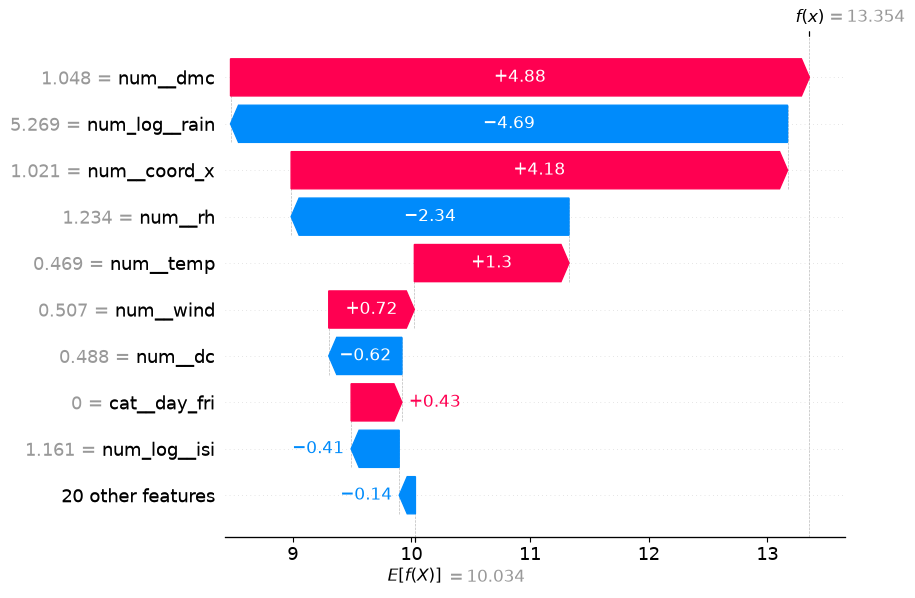

In [25]:
import shap
from sklearn.base import clone

pipe = best_model
pre = pipe.named_steps['preprocessing']
reg = pipe.named_steps['regressor']

dense = lambda m: m.toarray() if hasattr(m, 'toarray') else np.asarray(m)
train_transform = dense(pre.transform(X_train))
test_transform = dense(pre.transform(X_test))
names = list(pre.get_feature_names_out())

if isinstance(reg, Ridge):
    explainer = shap.explainers.Linear(reg, train_transform, feature_names=names)
else:
    explainer = shap.explainers.Tree(reg, train_transform, feature_names=names)

shap_test = explainer(test_transform)
shap_train = explainer(train_transform)

# One test observation
i = 1   # change to explain another row
base = np.ravel(shap_test.base_values)
row = shap.Explanation(values=shap_test.values[i],
                       base_values=float(base[i] if base.size > 1 else base[0]),
                       data=test_transform[i], feature_names=names)
shap.plots.waterfall(row)

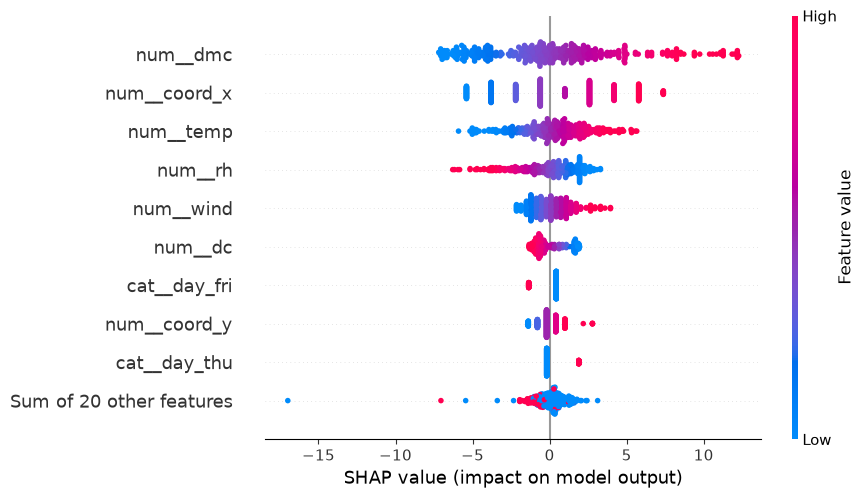

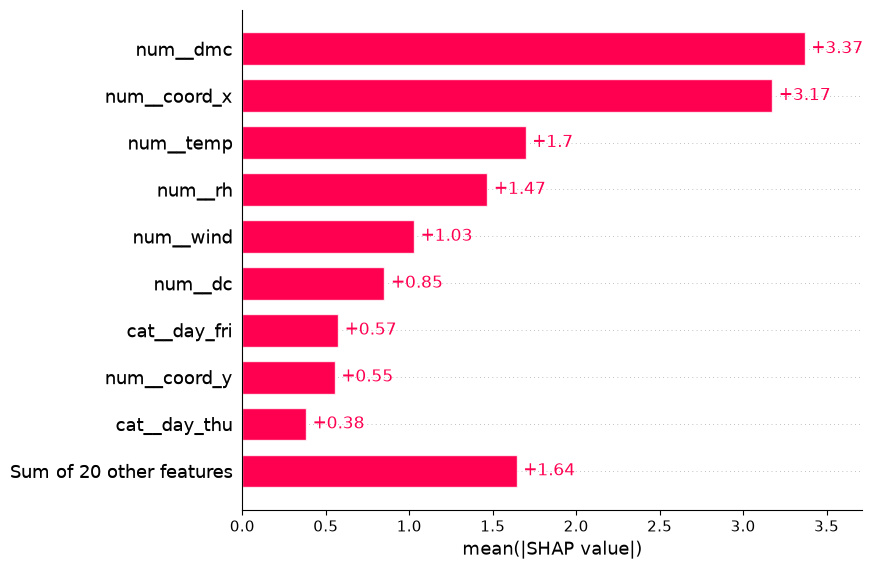

feature
dmc        3.368975
coord_x    3.174496
temp       1.697077
day        1.590353
rh         1.467699
wind       1.028517
dc         0.851196
coord_y    0.553590
month      0.553311
isi        0.236878
rain       0.180965
ffmc       0.037555
Name: mean_abs_shap, dtype: float64
Remove: ['isi', 'rain', 'ffmc']
CV RMSE, all features   : 38.89
CV RMSE, without those 3: 38.848


In [26]:
# Whole training set: most and least important
shap.plots.beeswarm(shap_train)
shap.plots.bar(shap_train)

def original_name(f):
    f = f.split('__', 1)[1]
    for c in ['month', 'day']:
        if f.startswith(c + '_'):
            return c
    return f

orig = np.array([original_name(f) for f in names])
imp = (pd.DataFrame({'feature': orig, 'mean_abs_shap': np.abs(shap_train.values).mean(axis=0)})
         .groupby('feature')['mean_abs_shap'].sum().sort_values(ascending=False))
print(imp)

# Test removing the 3 weakest features
drop = list(imp.index[-3:])
keep = np.where(~np.isin(orig, drop))[0]
cv = lambda cols: -cross_val_score(clone(reg), train_transform[:, cols], y_train, cv=5,
                                   scoring='neg_root_mean_squared_error').mean()
print('Remove:', drop)
print('CV RMSE, all features   :', round(cv(np.arange(len(names))), 3))
print('CV RMSE, without those 3:', round(cv(keep), 3))

**Explaining one prediction.** I picked row 1 from the test set. The model predicted a burned area of about 12.7 hectares, but the actual value was 0.0 hectares, so the model was off for this row. The average prediction over the data is 9.85, so this row was pushed up by about 2.9. In the waterfall plot, the features that pushed the prediction the most were rain, coord_x and dmc. Rain pushed the prediction down by 4.5, because this row had a relatively high rain value (scaled value 5.27). Coord_x pushed it up by 4.19 and dmc pushed it up by 3.13. Relative humidity (rh) pushed it down by 1.81 and temperature pushed it up by 1.4. The rest of the features changed it only a little.

**Which features matter overall.** To see this across all of the training data, I used the bar plot and the beeswarm plot. The most important features were coord_x (mean absolute SHAP of 3.18), dmc (2.51) and temp (1.82). They were followed by day of the week (1.63, all the day columns added together), rh (1.14) and wind (1.08). The least important features were isi (0.35), rain (0.17) and ffmc (0.06).

**Which features I would remove.** I would remove isi, rain and ffmc, because their SHAP values are very close to zero, so they do not really change the predictions. To check this, I trained the model again without those features and compared the cross-validated RMSE. With all features it was 38.95, and without them it was 38.91. The RMSE staye about the same (it was slightly lower), so those features were not helping and removing them is fine.

In [27]:
print('Actual area:', y_test.iloc[1])
print('Predicted  :', round(float(best_model.predict(X_test.iloc[[1]])[0]), 2))

Actual area: 0.0
Predicted  : 13.35


## Criteria

The [rubric](./assignment_2_rubric_clean.xlsx) contains the criteria for assessment.

## Submission Information

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.

### Submission Parameters:
* Submission Due Date: `HH:MM AM/PM - DD/MM/YYYY`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb) should be populated and should be the only change in your pull request.
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/production/pull/<pr_id>`
    * Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.

Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.

If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at the `help` channel. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.

# Reference

Cortez,Paulo and Morais,Anbal. (2008). Forest Fires. UCI Machine Learning Repository. https://doi.org/10.24432/C5D88D.